# 05 · Model benchmark

**Question:** which model family predicts Severity 4 best from conditions known at report
time, by how much, and at what cost?

**How the numbers were produced** (`src/accidents/benchmark.py`, run once with
`uv run python -m accidents.benchmark`; this notebook only reads its outputs):

- Eight families: a prior-only dummy, logistic regression on splines and Fourier terms,
  an Explainable Boosting Machine (glass-box GAM), LightGBM, XGBoost, CatBoost, and the
  deep tabular models RealMLP and TabM.
- **Equal tuning budget:** the library defaults plus 25 Optuna (TPE) trials per family,
  all fitted on the same 400k training rows and scored by average precision (AP) on the
  same 200k validation rows.
- Early stopping uses the last two training months (Feb–Mar 2022), never the validation
  months. The best configuration is refitted on all training rows and scored on all
  774,383 validation rows. **Test months are not touched here.**
- Uncertainty: 95% intervals from 1,000 bootstrap resamples of whole *days*, because
  accidents on the same day share weather and traffic. Every model is scored on the same
  resamples, so differences between models are paired.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from IPython.display import display
from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve, roc_curve

from accidents import benchmark, config, evaluate, export, models, plots

plots.use_style()
pd.set_option("display.width", 160)
RESULTS = benchmark.OUT

ORDER = ["dummy", "logistic", "ebm", "lightgbm", "xgboost", "catboost", "realmlp", "tabm"]
LABELS = {
    "dummy": "Dummy (prior)",
    "logistic": "Logistic + splines",
    "ebm": "EBM (glass-box)",
    "lightgbm": "LightGBM",
    "xgboost": "XGBoost",
    "catboost": "CatBoost",
    "realmlp": "RealMLP",
    "tabm": "TabM",
}
COLOR = {name: plots.SERIES[i] for i, name in enumerate(ORDER[1:])}  # fixed per model
COLOR["dummy"] = plots.MUTED

results = {}
predictions = {}
for name in ORDER:
    file = RESULTS / f"{name}.json"
    if file.exists():
        results[name] = json.loads(file.read_text())
        predictions[name] = pd.read_parquet(RESULTS / f"{name}_valid.parquet")
names = list(results)
print("models with results:", names)

table = pd.read_parquet(config.MODEL_TABLE, columns=["id", "start_time", "split"])
valid_days = table.loc[table["split"] == "valid"].set_index("id")["start_time"].dt.normalize()
first = predictions[names[0]]
y = first["y"].to_numpy()
days = valid_days.loc[first["id"]].to_numpy()
for name in names:  # every model scored the same rows in the same order
    assert (predictions[name]["id"].to_numpy() == first["id"].to_numpy()).all()
p = {name: predictions[name]["p"].to_numpy() for name in names}

models with results: ['dummy', 'logistic', 'ebm', 'lightgbm', 'xgboost', 'catboost', 'realmlp', 'tabm']


## 1 · Leaderboard on the validation months

In [2]:
samples = evaluate.bootstrap(y, p, days, n_boot=1000)
rows = []
for name in names:
    low, high = evaluate.interval(samples[name])
    r = results[name]
    rows.append({
        "model": LABELS[name], "exportable": models.MODELS[name].exportable,
        **evaluate.scores(y, p[name]), "ap_low": low, "ap_high": high,
        "default_ap_tuning": r["default_ap"], "tuned_ap_tuning": r["best_ap"],
        "fit_s": r["fit_seconds"], "predict_s": r["predict_seconds"],
        "size_mb": r["model_megabytes"],
    })  # fmt: skip
leaderboard = (
    pd.DataFrame(rows).set_index("model").sort_values("average_precision", ascending=False)
)
display(leaderboard.round(4))

,exportable,average_precision,roc_auc,log_loss,brier,ece,ap_low,ap_high,default_ap_tuning,tuned_ap_tuning,fit_s,predict_s,size_mb
model,,,,,,,,,,,,,
TabM,False,0.1876,0.8579,0.1014,0.0250,0.0045,0.1826,0.1937,0.1365,0.1882,759.9972,8.1318,1.6413
LightGBM,True,0.1864,0.8536,0.1020,0.0250,0.0043,0.1809,0.1928,0.1783,0.1887,14.3398,2.8626,2.6503
CatBoost,False,0.1863,0.8550,0.1019,0.0250,0.0044,0.1811,0.1921,0.1883,0.1950,130.0574,2.7368,23.2272
XGBoost,True,0.1842,0.8490,0.1027,0.0251,0.0043,0.1779,0.1913,0.1742,0.1873,7.9129,0.8496,6.3630
RealMLP,False,0.1829,0.8575,0.1015,0.0250,0.0029,0.1785,0.1877,0.1819,0.1851,320.3670,2.2476,2.5022
EBM (glass-box),True,0.1717,0.8493,0.1040,0.0255,0.0037,0.1671,0.1772,0.1694,0.1737,2619.4649,0.2522,1.4227
Logistic + splines,False,0.1669,0.8359,0.1051,0.0254,0.0040,0.1625,0.1721,0.1461,0.1670,9.3434,2.3373,0.0233
Dummy (prior),True,0.0284,0.5000,0.1296,0.0277,0.0066,0.0270,0.0301,0.0286,0.0286,0.0267,0.0092,0.0014


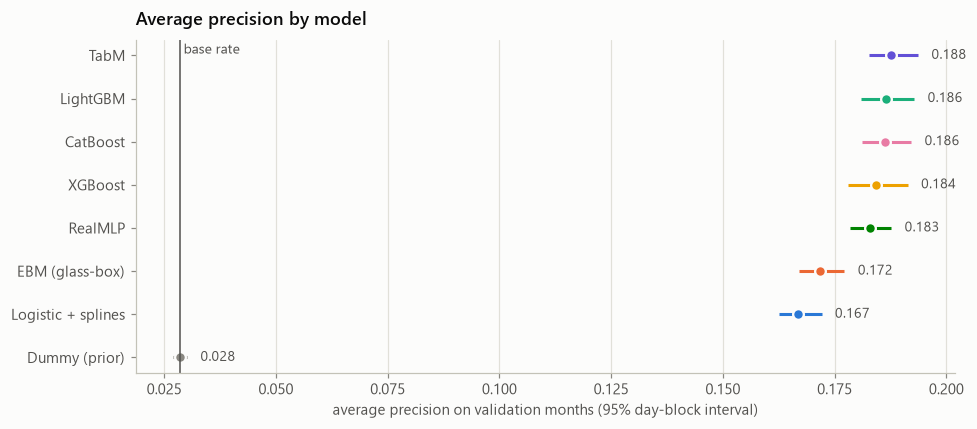

In [3]:
ordered = leaderboard.sort_values("average_precision")
fig, ax = plt.subplots(figsize=(9, 4))
yy = np.arange(len(ordered))
inverse = {v: k for k, v in LABELS.items()}
for i, (label, row) in enumerate(ordered.iterrows()):
    color = COLOR[inverse[label]]
    ax.hlines(i, row["ap_low"], row["ap_high"], color=color, linewidth=2)
    ax.plot(
        row["average_precision"],
        i,
        "o",
        color=color,
        markeredgecolor=plots.SURFACE,
        markeredgewidth=1.5,
        markersize=7,
    )
    ax.text(
        row["ap_high"] + 0.003,
        i,
        f"{row['average_precision']:.3f}",
        va="center",
        color=plots.INK_SECONDARY,
        fontsize=9,
    )
ax.axvline(y.mean(), color=plots.INK_SECONDARY, linewidth=1)
ax.text(
    y.mean(),
    0.99,
    " base rate",
    transform=ax.get_xaxis_transform(),
    va="top",
    color=plots.INK_SECONDARY,
    fontsize=9,
)
ax.set_yticks(yy, ordered.index)
ax.set_xlabel("average precision on validation months (95% day-block interval)")
ax.set_title("Average precision by model")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 2 · Are the differences real? Paired bootstrap against the leader

For each model, the leader's AP minus that model's AP on the same resampled days. An
interval that excludes zero means the gap is larger than day-to-day noise.

,gap,low,high,real difference
model,,,,
LightGBM,0.0012,-0.0010,0.0036,False
CatBoost,0.0013,-0.0010,0.0036,False
XGBoost,0.0035,-0.0003,0.0079,False
RealMLP,0.0047,0.0026,0.0070,True
EBM (glass-box),0.0159,0.0131,0.0189,True
Logistic + splines,0.0207,0.0174,0.0244,True
Dummy (prior),0.1592,0.1542,0.1647,True


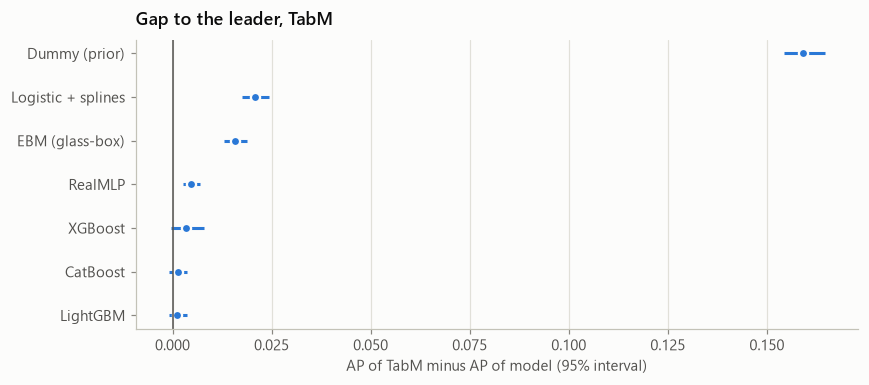

In [4]:
leader = inverse[leaderboard.index[0]]
diff_rows = []
for name in names:
    if name == leader:
        continue
    gap = samples[leader] - samples[name]
    low, high = evaluate.interval(gap)
    diff_rows.append(
        {
            "model": LABELS[name],
            "gap": gap.mean(),
            "low": low,
            "high": high,
            "real difference": low > 0,
        }
    )
differences = pd.DataFrame(diff_rows).set_index("model").sort_values("gap")
display(differences.round(4))

fig, ax = plt.subplots(figsize=(8, 3.6))
yy = np.arange(len(differences))
ax.hlines(yy, differences["low"], differences["high"], color=plots.SERIES[0], linewidth=2)
ax.plot(
    differences["gap"],
    yy,
    "o",
    color=plots.SERIES[0],
    markeredgecolor=plots.SURFACE,
    markeredgewidth=1.5,
)
ax.axvline(0, color=plots.INK_SECONDARY, linewidth=1)
ax.set_yticks(yy, differences.index)
ax.set_xlabel(f"AP of {LABELS[leader]} minus AP of model (95% interval)")
ax.set_title(f"Gap to the leader, {LABELS[leader]}")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 3 · Precision–recall and ROC curves

With a 2.8% base rate the precision–recall curve is the honest view: it shows how many
alerts are real at each level of recall. ROC curves look flattering at low prevalence.

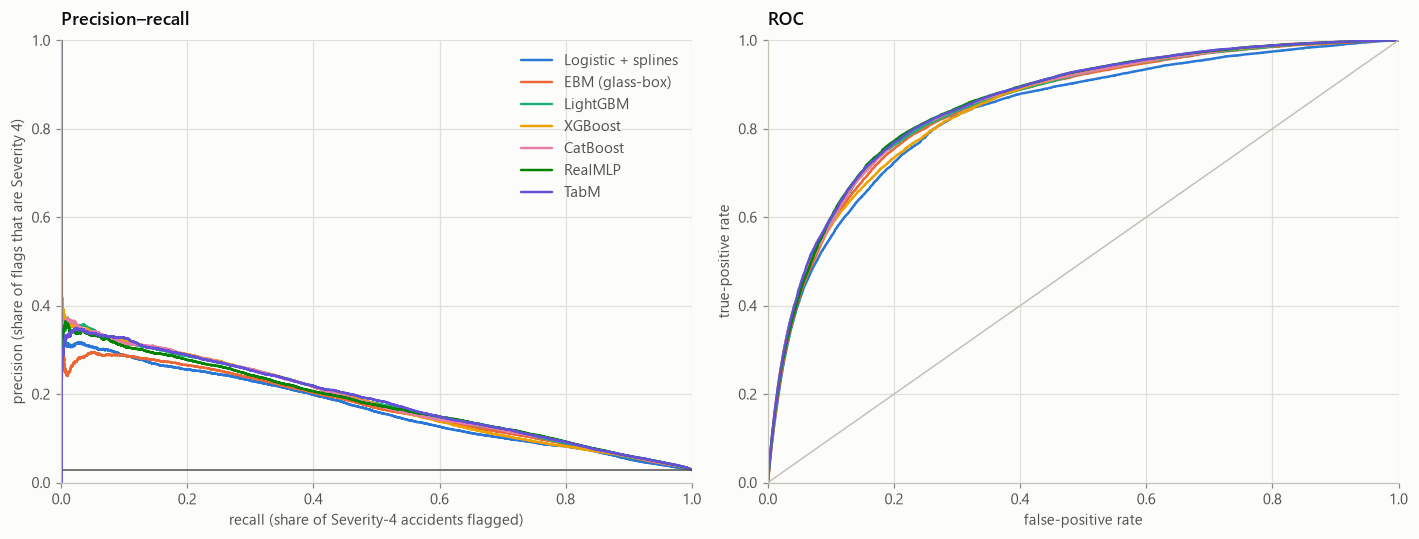

In [5]:
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5))
for name in names:
    if name == "dummy":
        continue
    precision, recall, _ = precision_recall_curve(y, p[name])
    left.plot(recall, precision, color=COLOR[name], linewidth=1.6, label=LABELS[name])
    fpr, tpr, _ = roc_curve(y, p[name])
    right.plot(fpr, tpr, color=COLOR[name], linewidth=1.6, label=LABELS[name])
left.axhline(y.mean(), color=plots.INK_SECONDARY, linewidth=1)
left.set(
    xlabel="recall (share of Severity-4 accidents flagged)",
    ylabel="precision (share of flags that are Severity 4)",
    title="Precision–recall",
    xlim=(0, 1),
    ylim=(0, 1),
)
right.plot([0, 1], [0, 1], color=plots.BASELINE, linewidth=1)
right.set(
    xlabel="false-positive rate", ylabel="true-positive rate", title="ROC", xlim=(0, 1), ylim=(0, 1)
)
left.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 4 · Calibration before any recalibration

Predicted probability against the observed rate in 15 equal-count bins, on log axes
because almost all predictions sit below 10%. Points on the diagonal mean a model's
probabilities can be read at face value. Notebook 06 recalibrates the chosen model.

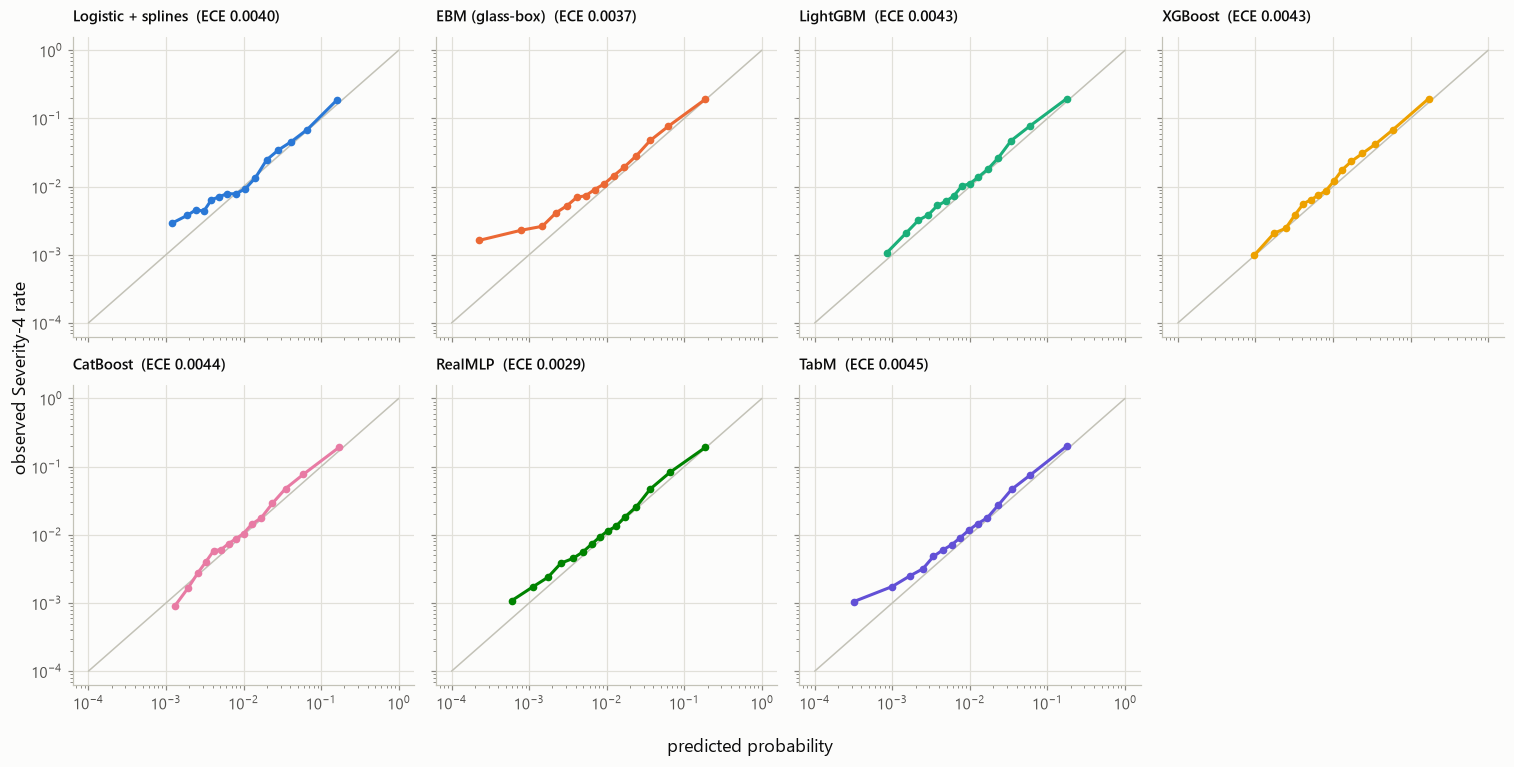

In [6]:
shown = [n for n in names if n != "dummy"]
cols = 4
fig, axes = plt.subplots(
    int(np.ceil(len(shown) / cols)), cols, figsize=(14, 7), sharex=True, sharey=True, squeeze=False
)
for ax, name in zip(axes.flat, shown, strict=False):
    observed, predicted = calibration_curve(y, p[name], n_bins=15, strategy="quantile")
    ax.plot([1e-4, 1], [1e-4, 1], color=plots.BASELINE, linewidth=1)
    ax.plot(predicted, observed, "o-", color=COLOR[name], markersize=4)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(
        f"{LABELS[name]}  (ECE {evaluate.expected_calibration_error(y, p[name]):.4f})", fontsize=10
    )
for ax in axes.flat[len(shown) :]:
    ax.set_visible(False)
fig.supxlabel("predicted probability")
fig.supylabel("observed Severity-4 rate")
plt.tight_layout()
plt.show()

## 5 · What tuning bought, and what more data buys

Left: AP of each family's library defaults against its best tuned configuration (both on
the 400k/200k tuning rows). Right: validation AP when the tuned configuration is trained on
50k, 200k and 800k rows and on all training rows.

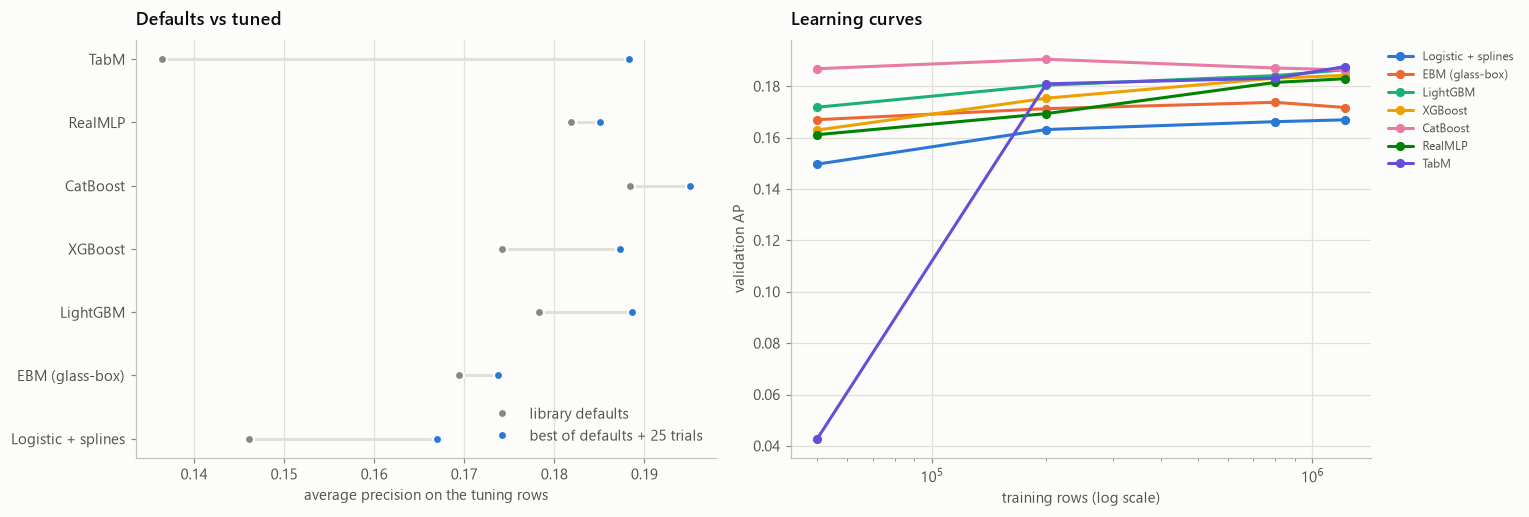

In [7]:
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 4.8))
tuned = [n for n in names if n != "dummy"]
yy = np.arange(len(tuned))
for i, name in enumerate(tuned):
    r = results[name]
    left.hlines(i, r["default_ap"], r["best_ap"], color=plots.GRID, linewidth=2)
    left.plot(
        r["default_ap"],
        i,
        "o",
        color=plots.MUTED,
        markeredgecolor=plots.SURFACE,
        markeredgewidth=1.5,
        label="library defaults" if i == 0 else None,
    )
    left.plot(
        r["best_ap"],
        i,
        "o",
        color=plots.SERIES[0],
        markeredgecolor=plots.SURFACE,
        markeredgewidth=1.5,
        label=f"best of defaults + {benchmark.N_TRIALS} trials" if i == 0 else None,
    )
left.set_yticks(yy, [LABELS[n] for n in tuned])
left.set_xlabel("average precision on the tuning rows")
left.set_title("Defaults vs tuned")
left.legend(loc="lower right")
left.grid(axis="y", visible=False)
for name in tuned:
    curve = {int(k): v for k, v in results[name]["learning_curve"].items()}
    sizes = sorted(curve)
    right.plot(
        sizes, [curve[s] for s in sizes], "o-", color=COLOR[name], label=LABELS[name], markersize=5
    )
right.set_xscale("log")
right.set_xlabel("training rows (log scale)")
right.set_ylabel("validation AP")
right.set_title("Learning curves")
right.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()
plt.show()

## 6 · Tuning histories

Best AP so far after each Optuna trial. A curve that is still rising at trial 25 means
that family would gain from a larger budget.

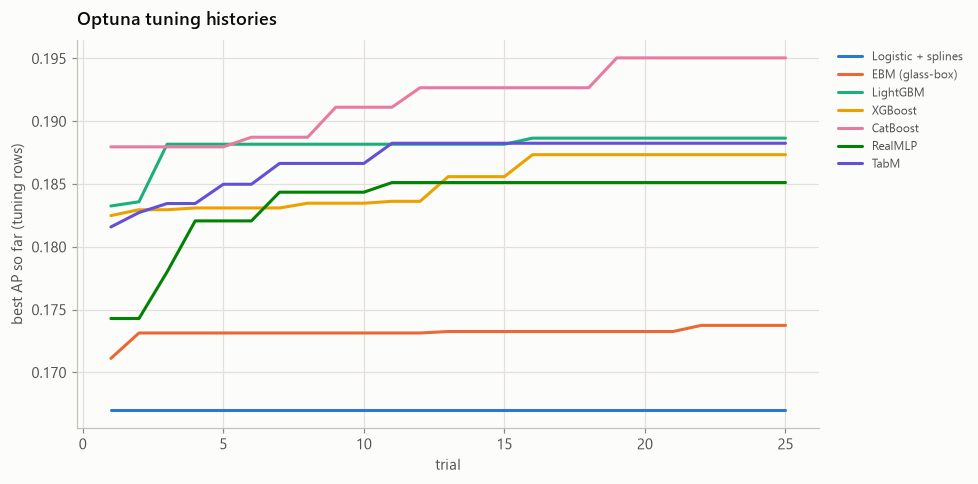

In [8]:
storage = f"sqlite:///{(RESULTS / 'optuna.db').as_posix()}"
fig, ax = plt.subplots(figsize=(9, 4.5))
for name in tuned:
    try:
        study = optuna.load_study(study_name=name, storage=storage)
    except KeyError:
        continue
    values = [t.value for t in study.trials if t.value is not None]
    if values:
        ax.plot(
            np.arange(1, len(values) + 1),
            np.maximum.accumulate(values),
            color=COLOR[name],
            label=LABELS[name],
        )
ax.set_xlabel("trial")
ax.set_ylabel("best AP so far (tuning rows)")
ax.set_title("Optuna tuning histories")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()
plt.show()

## 7 · Accuracy against cost

Validation AP against training time (log scale). Filled markers can be exported to run in
the browser dashboard; hollow markers cannot without extra machinery.

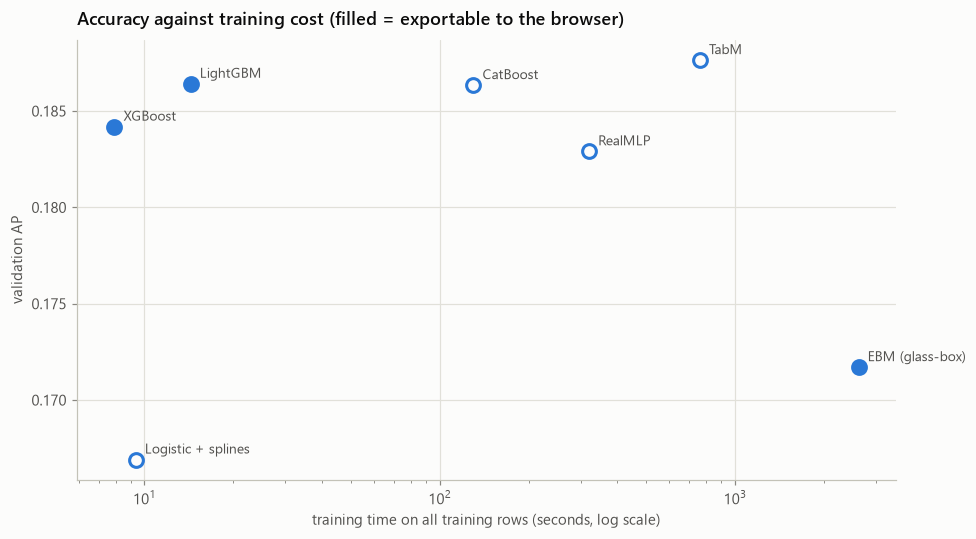

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
for name in tuned:
    r = results[name]
    exportable = models.MODELS[name].exportable
    ax.plot(
        r["fit_seconds"],
        r["valid_ap"],
        "o",
        markersize=9,
        color=plots.SERIES[0] if exportable else plots.SURFACE,
        markeredgecolor=plots.SERIES[0],
        markeredgewidth=2,
    )
    ax.annotate(
        LABELS[name],
        (r["fit_seconds"], r["valid_ap"]),
        xytext=(6, 4),
        textcoords="offset points",
        fontsize=9,
        color=plots.INK_SECONDARY,
    )
ax.set_xscale("log")
ax.set_xlabel("training time on all training rows (seconds, log scale)")
ax.set_ylabel("validation AP")
ax.set_title("Accuracy against training cost (filled = exportable to the browser)")
plt.tight_layout()
plt.show()

## 8 · Applying the selection rule

The dashboard scores accidents in the browser, so the deployed model must run there
exactly as in Python. Decision record 0001 wrote the rule before the run: highest
validation AP among exportable models, with a non-exportable winner shipped through ONNX
Runtime Web if it led beyond noise.

**Restated on 2026-10-15, before the final validation scores existed:** a check on the
smoke-test CatBoost model found that its ONNX export refuses categorical features and its
JSON export needs 244 hashed target-statistic tables, so CatBoost has no exact browser
path and is not exportable. The rule therefore ships the best exportable model, and
reports any non-exportable model's lead, with its paired 95% interval, as the measured
cost of portability. Exportability comes from `src/accidents/models.py`.

In [10]:
exportable = [n for n in names if models.MODELS[n].exportable and n != "dummy"]
best_exportable = max(exportable, key=lambda n: results[n]["valid_ap"])
best_overall = max((n for n in names if n != "dummy"), key=lambda n: results[n]["valid_ap"])
gap = samples[best_overall] - samples[best_exportable]
low, high = evaluate.interval(gap)
chosen = best_exportable
if best_overall == best_exportable:
    reason = f"{LABELS[chosen]} has the highest validation AP and runs in the browser"
elif low <= 0:
    reason = (
        f"{LABELS[chosen]} is the best exportable model; {LABELS[best_overall]}'s lead "
        f"({gap.mean():.4f} AP, 95% interval [{low:.4f}, {high:.4f}]) is within noise"
    )
else:
    reason = (
        f"{LABELS[chosen]} is the best exportable model; {LABELS[best_overall]} leads by "
        f"{gap.mean():.4f} AP, 95% interval [{low:.4f}, {high:.4f}]: the measured cost of "
        f"in-browser scoring"
    )
selection = {
    "chosen": chosen,
    "best_exportable": best_exportable,
    "best_overall": best_overall,
    "gap_mean": float(gap.mean()),
    "gap_low": low,
    "gap_high": high,
    "portability_cost_beyond_noise": bool(best_overall != best_exportable and low > 0),
    "reason": reason,
}
(RESULTS / "selection.json").write_text(json.dumps(selection, indent=2))
print(json.dumps(selection, indent=2))

{
  "chosen": "lightgbm",
  "best_exportable": "lightgbm",
  "best_overall": "tabm",
  "gap_mean": 0.001218122728271151,
  "gap_low": -0.0010029240989252676,
  "gap_high": 0.003555744090916847,
  "portability_cost_beyond_noise": false,
  "reason": "LightGBM is the best exportable model; TabM's lead (0.0012 AP, 95% interval [-0.0010, 0.0036]) is within noise"
}


## Saved for the dashboard

In [11]:
(RESULTS / "leaderboard.json").write_text(
    json.dumps(
        {
            "base_rate": float(y.mean()),
            "leaderboard": export.records(leaderboard),
            "differences": export.records(differences),
            "learning_curves": {n: results[n]["learning_curve"] for n in tuned},
        },
        indent=2,
    )
)
print("saved", RESULTS / "leaderboard.json")

saved data\processed\benchmark\leaderboard.json


## Decisions and evidence

_Written from the outputs above._

1. **Four very different families tie at the top.** On the 774,383 validation accidents
   (base rate 2.84%), TabM reaches AP 0.188 (95% interval 0.183–0.194), LightGBM 0.186,
   CatBoost 0.186 and XGBoost 0.184. Their gaps to TabM are within noise (LightGBM 0.0012,
   interval −0.0010 to 0.0036; XGBoost 0.0035, −0.0003 to 0.0079). RealMLP (0.183), the EBM
   (0.172) and logistic regression (0.167) trail by margins beyond noise. When a deep
   ensemble, three boosting libraries and a tuned MLP land within 0.005 of each other, the
   ceiling is set by what the features know, not by the model family.
2. **The best models reach about 6.6 times the base rate, and none is sharp.** AP near 0.19
   is precision averaged over every recall level: catching most Severity-4 accidents means
   most flags are false alarms (notebook 06 measures this at each cost ratio).
   ROC-AUC is 0.836–0.858. Raw probabilities are already close to calibrated (expected
   calibration error 0.003–0.005).
3. **Tuning mattered most where defaults fail.** TabM's library defaults score 0.137 on the
   tuning rows and 0.188 after 25 trials; logistic regression gains 0.021; the boosters gain
   0.007–0.013; CatBoost's defaults were already the best starting point (0.188). CatBoost
   was still improving at trial 19, so its tuned score is the least saturated.
4. **More data still helps most models.** From 50k to 1.2M training rows LightGBM rises
   from 0.172 to 0.186, XGBoost from 0.163 to 0.184 and RealMLP from 0.161 to 0.183. TabM
   fails to learn from 50k rows (0.043) and catches up from 200k. Two exceptions: the EBM
   peaks at 800k (0.174, then 0.172), and CatBoost peaks at 200k (0.191, then 0.186), which
   suggests its configuration, tuned on 400k rows, regularises too little for the full set.
   Every point is scored on the same validation rows.
5. **Cost differs by two orders of magnitude for the same accuracy.** Training on all rows
   takes 8 s (XGBoost) and 14 s (LightGBM) on a CPU, against 130 s (CatBoost), 320 s
   (RealMLP) and 760 s (TabM) on a GPU, and 44 minutes for the EBM.
6. **Decision: LightGBM ships.** The rule written before the scores selects the best model
   that can run in the browser. TabM leads it by 0.0012 AP, inside the noise, so in-browser
   scoring costs no measurable accuracy. The EBM is kept as the glass-box reference for
   notebook 07.